In [29]:
import numpy as np
import xarray as xr
import os
import glob
from matplotlib import pyplot as plt
import echopype as ep  # we recommend using "ep"

In [30]:
output_path = r"P:\11212489-008-acoustic-ch4-test\data_processing\converted_files_261021_wc_experiment_01"

In [31]:
# read .nc files from the output path
nc_files = glob.glob(os.path.join(output_path, "*.nc"))

num = 0  # set the experiment number here

if num==0:
    exp_ = "exp01_01"
elif num==1:
    exp_ = "exp02_02"
elif num==2:
    exp_ = "exp03_03"
else:
    print("Invalid experiment number")


In [32]:
echodata = ep.open_converted(nc_files[num])      # create an EchoData object for the first .nc file

In [33]:
ds_Sv = ep.calibrate.compute_Sv(echodata, waveform_mode="BB", encode_mode="complex")

In [34]:
ds_Sv = (
    ds_Sv.assign_coords(
        {"range": ("range_sample", ds_Sv["echo_range"].isel(ping_time=0, channel=0).data)}
    )  # use first ping range
    .swap_dims({"range_sample": "range"})  # swap the dimension
)


ds_Sv["range"] = ds_Sv["range"].assign_attrs(
    {"long_name": "range", "units": "meter"}
)

In [35]:
sv = ds_Sv["Sv"]          # xarray.DataArray, dims: (channel, ping_time, range_sample)

sv.values                 # raw numpy array of Sv values (dB)
sv["ping_time"].values    # x-axis values
sv["range_sample"].values # y-axis values (or "echo_range" / "depth" if computed)
sv["channel"].values      # one panel per channel (the `row="channel"` facets)

array(['WBT Tube 291337-15 ES120-7CD_ES'], dtype='<U31')

In [36]:
sv_ch0 = sv.isel(channel=0)              # first panel
# or by name:
sv_ch0 = sv.sel(channel=sv["channel"].values[0])

matrix = sv_ch0.values  

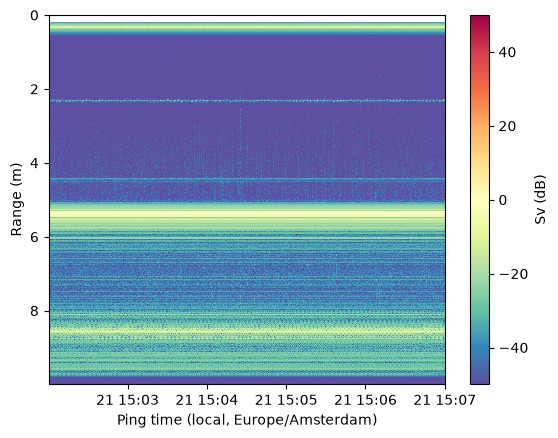

In [37]:
import pandas as pd

ping_time_utc = sv_ch0["ping_time"].values
range_sample = sv_ch0["range"].values
channel = sv_ch0["channel"].values

# Convert UTC -> Dutch local time (Europe/Amsterdam).
# The tz database handles the recent DST change (25 Oct 2026: CEST UTC+2 -> CET UTC+1) automatically.
ping_time = (pd.to_datetime(ping_time_utc)
             .tz_localize("UTC")
             .tz_convert("Europe/Amsterdam")
             .tz_localize(None))  # drop tz info so matplotlib shows local wall-clock time

# matrix has shape (ping_time, range) -> transpose so rows match the y-axis (range)
# pcolormesh accepts 1-D x and y directly, no meshgrid needed
plt.pcolormesh(ping_time, range_sample, matrix.T, shading='auto',
               cmap='Spectral_r', vmin=-50, vmax=50)

plt.colorbar(label='Sv (dB)')
plt.xlabel('Ping time (local, Europe/Amsterdam)')
plt.ylabel('Range (m)')
plt.gca().invert_yaxis()  # match yincrease=False from the xarray plot
plt.show()


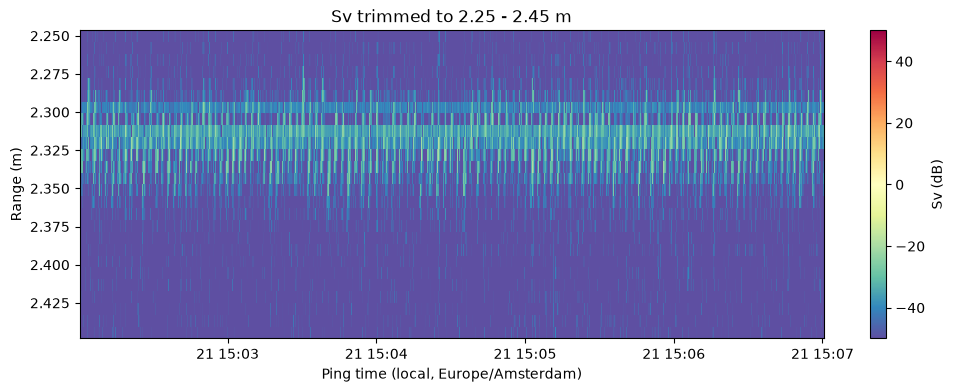

In [38]:
# Trimmed version: keep only the range interval 2.25 m to 2.45 m
mask = (range_sample >= 2.25) & (range_sample <= 2.45)

fig,ax = plt.subplots(figsize=(12, 4))

pcm = ax.pcolormesh(ping_time, range_sample[mask], matrix.T[mask, :], shading='auto',
                    cmap='Spectral_r', vmin=-50, vmax=50)
fig.colorbar(pcm, ax=ax, label='Sv (dB)')
ax.set_xlabel('Ping time (local, Europe/Amsterdam)')
ax.set_ylabel('Range (m)')
ax.set_title('Sv trimmed to 2.25 - 2.45 m')
ax.invert_yaxis()  # match yincrease=False from the xarray plot
plt.show()


In [39]:
# pandas DataFrame (long format: channel, ping_time, range_sample, Sv)
#df = sv.to_dataframe().reset_index()
#df

In [40]:
# --- Split the trimmed data into 5 s segments with 2.5 s overlap ---
seg_len = pd.Timedelta(seconds=5)
hop     = pd.Timedelta(seconds=2.5)   # step = seg_len - overlap = 2.5 s

mask = (range_sample >= 2.2) & (range_sample <= 2.5)
rng  = range_sample[mask]
data = matrix.T[mask, :]              # shape: (range, ping_time)

t0, t_end = ping_time[0], ping_time[-1]

segments = []   # list of (start, end, boolean ping index)
t = t0
while t < t_end:
    s, e = t, t + seg_len
    idx = (ping_time >= s) & (ping_time < e)
    if idx.sum() >= 2:                # need at least 2 pings to draw a mesh
        segments.append((s, e, idx))
    t += hop

print(f"{len(segments)} segments of 5 s (2.5 s overlap), "
      f"covering {t0.strftime('%H:%M:%S')} - {t_end.strftime('%H:%M:%S')}")

120 segments of 5 s (2.5 s overlap), covering 15:02:00 - 15:07:00


In [41]:
# --- Animate the segments ---
import matplotlib.animation as animation
import matplotlib.dates as mdates
from matplotlib import cm, colors
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(7, 6))

# one static colorbar shared by all frames
norm = colors.Normalize(vmin=-50, vmax=50)
fig.colorbar(cm.ScalarMappable(norm=norm, cmap='Spectral_r'), ax=ax, label='Sv (dB)')

def draw_frame(i):
    ax.clear()
    s, e, idx = segments[i]
    # x = range (m), y = ping time -> data must be (time, range), hence the .T
    ax.pcolormesh(rng, ping_time[idx], data[:, idx].T, shading='auto',
                  cmap='Spectral_r', norm=norm)
    ax.set_xlabel('Range (m)')
    ax.set_ylabel('Ping time (local, Europe/Amsterdam)')
    ax.set_title(f"Segment {i+1}/{len(segments)}: "
                 f"{s.strftime('%H:%M:%S')} - {e.strftime('%H:%M:%S')}")
    # short, readable time stamps: one tick per second, HH:MM:SS
    ax.yaxis.set_major_locator(mdates.SecondLocator(interval=1))
    ax.yaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
    ax.tick_params(axis='y', labelsize=8)
    ax.invert_yaxis()  # waterfall style: earliest ping at the top, time flows downward

anim = animation.FuncAnimation(fig, draw_frame, frames=len(segments), interval=500)
plt.close(fig)          # avoid showing a duplicate static figure

HTML(anim.to_jshtml())  # interactive player in the notebook

# To save it as a file instead (requires pillow / ffmpeg):
anim.save(output_path+f'/sv_segments_2.25-2.45m_{exp_}.gif', writer='pillow', fps=2)
#anim.save(output_path+'/sv_segments_2.25-2.45m.mp4', writer='ffmpeg', fps=2)

In [42]:
# --- Binary (mask) version of the trimmed data based on an Sv threshold ---
sv_threshold = -35.0   # dB: pixels with Sv >= threshold -> 1 (target/bubble), else 0

data_bin = (data >= sv_threshold).astype(int)   # same shape as data: (range, ping_time)
print(f"{data_bin.mean()*100:.1f}% of pixels above {sv_threshold} dB")

# To animate the mask instead of Sv: in the animation cell replace
#   data -> data_bin   and   norm=norm -> vmin=0, vmax=1, cmap='gray_r'

4.6% of pixels above -35.0 dB


In [43]:
# --- Animate the binary mask (same segments: 5 s windows, 2.5 s overlap) ---
fig, ax = plt.subplots(figsize=(10, 6))

# one static two-level colorbar shared by all frames
norm_bin = colors.Normalize(vmin=0, vmax=1)
cbar = fig.colorbar(cm.ScalarMappable(norm=norm_bin, cmap='viridis'),
                    ax=ax, ticks=[0, 1], label='Mask')
cbar.ax.set_yticklabels(['below', 'above'])

def draw_mask_frame(i):
    ax.clear()
    s, e, idx = segments[i]
    # x = range (m), y = ping time -> data must be (time, range), hence the .T
    ax.pcolormesh(rng, ping_time[idx], data_bin[:, idx].T, shading='auto',
                  cmap='viridis', norm=norm_bin)
    ax.set_xlabel('Range (m)')
    ax.set_ylabel('Ping time (local, Europe/Amsterdam)')
    ax.set_title(f"Mask (Sv >= {sv_threshold} dB), segment {i+1}/{len(segments)}: "
                 f"{s.strftime('%H:%M:%S')} - {e.strftime('%H:%M:%S')}")
    # short, readable time stamps: one tick per second, HH:MM:SS
    ax.yaxis.set_major_locator(mdates.SecondLocator(interval=1))
    ax.yaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
    ax.tick_params(axis='y', labelsize=8)
    ax.invert_yaxis()  # waterfall style: earliest ping at the top

    # add grid
    ax.grid(True, which='both', linestyle='--', linewidth=0.5)

anim_mask = animation.FuncAnimation(fig, draw_mask_frame, frames=len(segments), interval=500)
plt.close(fig)          # avoid showing a duplicate static figure

HTML(anim_mask.to_jshtml())  # interactive player in the notebook

# To save it as a file instead (requires pillow / ffmpeg):
anim_mask.save(output_path+f'/sv_mask_segments_2.25-2.45m_{exp_}.gif', writer='pillow', fps=2)
# anim_mask.save('../outputs/figures/sv_mask_segments_2.25-2.45m.mp4', writer='ffmpeg', fps=2)

In [44]:
# --- Animate the binary mask (same segments: 5 s windows, 2.5 s overlap) ---

In [45]:
# retrieve the time stamps from the image file names
from datetime import datetime
def get_timestamp_from_filename(filename):

    date_ = filename.split('\\')[-1].split('_')[0]
    yyyy = '20'+date_[:2]
    mm = date_[2:4]
    dd = date_[4:6]

    time_ = filename.split('\\')[-1].split('-')[-1]
    hh = time_[:2]
    mi = time_[3:5]
    ss = time_[6:8]
    ms = time_[9:12]  # assuming milliseconds are present in the filename

    return datetime(int(yyyy), int(mm), int(dd), int(hh), int(mi), int(ss), int(ms)*1000)


In [46]:
# load images

path_png = rf'P:\11212489-008-acoustic-ch4-test\data_processing\images_files_261021_wc_{exp_}'
import os
images = [os.path.join(path_png, f) for f in os.listdir(path_png) if f.endswith('.png')]
#images.sort()  # optional: sort the images by filename

dates_images = [get_timestamp_from_filename(f) for f in images]

# sort dates
dates_images.sort()


In [47]:
img_times = pd.DatetimeIndex(dates_images)
inside = (img_times >= ping_time[0]) & (img_times <= ping_time[-1])
print(f"Images inside ping_time window: {inside.sum()} / {len(img_times)}")

Images inside ping_time window: 444 / 444


In [48]:
# --- Animate Sv segments with the camera frame alongside (common time window only) ---
import matplotlib.animation as animation
import matplotlib.dates as mdates
from PIL import Image
from matplotlib import cm, colors
from IPython.display import HTML

# images sorted by timestamp (keep file <-> time pairing)
img_pairs = sorted(zip(images, (get_timestamp_from_filename(f) for f in images)), key=lambda p: p[1])
img_files = [p[0] for p in img_pairs]
img_times = pd.DatetimeIndex([p[1] for p in img_pairs])

# common time window between pings and camera
t0 = max(ping_time[0], img_times[0])
t_end = min(ping_time[-1], img_times[-1])
print(f"Common window: {t0} -> {t_end}")

# 5 s segments with 2.5 s overlap, inside the common window
seg_len = pd.Timedelta(seconds=5)
hop = pd.Timedelta(seconds=2.5)

segments_cam = []   # (start, end, ping index, image index nearest to segment midpoint)
t = t0
while t < t_end:
    s, e = t, min(t + seg_len, t_end)
    idx = (ping_time >= s) & (ping_time < e)
    mid = s + (e - s) / 2
    j = int(np.argmin(np.abs(img_times - mid)))
    if idx.sum() >= 2:
        segments_cam.append((s, e, idx, j))
    t += hop
print(f"{len(segments_cam)} segments in the common window")

fig, (ax_sv, ax_img) = plt.subplots(1, 2, figsize=(13, 6), width_ratios=[1, 1.2])

norm = colors.Normalize(vmin=-50, vmax=50)
fig.colorbar(cm.ScalarMappable(norm=norm, cmap="Spectral_r"), ax=ax_sv, label="Sv (dB)")

def draw_cam_frame(i):
    ax_sv.clear(); ax_img.clear()
    s, e, idx, j = segments_cam[i]

    # left: Sv waterfall (x = range, y = ping time)
    ax_sv.pcolormesh(rng, ping_time[idx], data[:, idx].T, shading="auto",
                     cmap="Spectral_r", norm=norm)
    # mark the timestamp of the displayed camera frame
    ax_sv.axhline(img_times[j], color="k", linestyle="--", linewidth=1.2)
    ax_sv.set_xlabel("Range (m)")
    ax_sv.set_ylabel("Ping time (local, Europe/Amsterdam)")
    ax_sv.set_title(f"Sv segment {i+1}/{len(segments_cam)}: "
                    f"{s.strftime('%H:%M:%S')} - {e.strftime('%H:%M:%S')}")
    ax_sv.yaxis.set_major_locator(mdates.SecondLocator(interval=1))
    ax_sv.yaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
    ax_sv.tick_params(axis="y", labelsize=8)
    ax_sv.invert_yaxis()   # waterfall style: earliest ping at the top

    # right: camera frame nearest the segment midpoint, in its original colors
    # (PNGs are single-channel 'L'; converting to RGB keeps the original look
    #  instead of matplotlib's false-color viridis mapping of 2D arrays). Rotate image 180 degrees.
    ax_img.imshow(Image.open(img_files[j]).convert('RGB').rotate(180))
    ax_img.set_title(f"Camera {img_times[j].strftime('%H:%M:%S.%f')[:-3]} "
                     f"(frame {j+1}/{len(img_files)})")
    ax_img.axis("off")

anim_cam = animation.FuncAnimation(fig, draw_cam_frame, frames=len(segments_cam), interval=500)
plt.close(fig)

HTML(anim_cam.to_jshtml())

# To save it as a file instead (requires pillow / ffmpeg):
anim_cam.save(os.path.join(output_path, f"sv_camera_segments_{exp_}.gif"), writer="pillow", fps=2)
# anim_cam.save(os.path.join(output_path, "sv_camera_segments.mp4"), writer="ffmpeg", fps=2)


Common window: 2026-10-21 15:05:02.072000 -> 2026-10-21 15:06:01.537000
24 segments in the common window


In [49]:
# add video for the masked Sv segments with the camera frame alongside (common time window only)
fig, (ax_sv, ax_img) = plt.subplots(1, 2, figsize=(13, 6), width_ratios=[1, 1.2])

def draw_mask_cam_frame(i):
    ax_sv.clear(); ax_img.clear()
    s, e, idx, j = segments_cam[i]

    # left: masked Sv waterfall (x = range, y = ping time)
    ax_sv.pcolormesh(rng, ping_time[idx], mask[:, idx].T, shading="auto",
                     cmap="Spectral_r", norm=norm)
    ax_sv.axhline(img_times[j], color="k", linestyle="--", linewidth=1.2)
    ax_sv.set_xlabel("Range (m)")
    ax_sv.set_ylabel("Ping time (local, Europe/Amsterdam)")
    ax_sv.set_title(f"Masked Sv segment {i+1}/{len(segments_cam)}: "
                    f"{s.strftime('%H:%M:%S')} - {e.strftime('%H:%M:%S')}")
    ax_sv.yaxis.set_major_locator(mdates.SecondLocator(interval=1))
    ax_sv.yaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
    ax_sv.tick_params(axis="y", labelsize=8)
    ax_sv.invert_yaxis()

    # right: camera frame nearest the segment midpoint
    ax_img.imshow(Image.open(img_files[j]).convert('RGB').rotate(180))
    ax_img.set_title(f"Camera {img_times[j].strftime('%H:%M:%S.%f')[:-3]} "
                     f"(frame {j+1}/{len(img_files)})")
    ax_img.axis("off")

anim_mask_cam = animation.FuncAnimation(fig, draw_mask_cam_frame, frames=len(segments_cam), interval=500)
plt.close(fig)

HTML(anim_mask_cam.to_jshtml())

anim_mask_cam.save(os.path.join(output_path, f"sv_mask_camera_segments_{exp_}.gif"), writer="pillow", fps=2)

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed